# BÀI THỰC HÀNH 13: MÔ HÌNH PHƯƠNG TRÌNH CẤU TRÚC (SEM - STRUCTURAL EQUATION MODELING)
**Môn học:** Phân tích Dữ liệu Nâng cao / Kinh tế lượng & Thống kê ứng dụng  
**Chủ đề:** Ứng dụng thư viện `semopy` để xây dựng, ước lượng và trực quan hóa mô hình SEM Political Democracy (Bollen, 1989)

---

### Giới thiệu bài toán & Bộ dữ liệu (Political Democracy Dataset)
Mô hình nghiên cứu mối quan hệ giữa **Công nghiệp hóa (Industrialization - 1960)** và **Mức độ dân chủ (Political Democracy)** tại hai thời điểm năm **1960** và năm **1965**.

#### 1. Các biến tiềm ẩn (Latent Variables):
* `ind60`: Biến tiềm ẩn ngoại sinh đại diện cho **Mức độ công nghiệp hóa năm 1960**.
* `dem60`: Biến tiềm ẩn nội sinh đại diện cho **Mức độ dân chủ chính trị năm 1960**.
* `dem65`: Biến tiềm ẩn nội sinh đại diện cho **Mức độ dân chủ chính trị năm 1965**.

#### 2. Các biến quan sát được (Observed Variables):
* **Đo lường công nghiệp hóa (1960):**
  * `x1`: Tổng sản phẩm quốc nội (GNP) bình quân đầu người, năm 1960.
  * `x2`: Mức tiêu thụ năng lượng bình quân đầu người, năm 1960.
  * `x3`: Tỷ lệ lực lượng lao động làm việc trong ngành công nghiệp, năm 1960.
* **Đo lường dân chủ chính trị (1960):**
  * `y1`: Tự do báo chí, năm 1960.
  * `y2`: Tự do đối lập chính trị, năm 1960.
  * `y3`: Sự công bằng của các cuộc bầu cử, năm 1960.
  * `y4`: Hiệu quả của cơ quan lập pháp được bầu, năm 1960.
* **Đo lường dân chủ chính trị (1965):**
  * `y5` – `y8`: Các biến tương ứng với `y1` – `y4`, được đo lường vào năm 1965.

## 1. Cài đặt các thư viện cần thiết
Cài đặt thư viện `semopy` (thư viện hàng đầu cho SEM trong Python) và `graphviz` để trực quan hóa sơ đồ đường dẫn (Path Diagram).

In [7]:
# Cài đặt thư viện semopy và graphviz
%pip install semopy graphviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\ACER\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 2. Import các thư viện & Thiết lập môi trường

In [8]:
import os
import sys
import pandas as pd
import numpy as np
import semopy
from semopy import Model, calc_stats, semplot
from IPython.display import Image, display

# Cấu hình đường dẫn Graphviz (dành cho Windows nếu chạy trên máy cục bộ)
possible_graphviz_paths = [
    r"C:\Program Files\Graphviz\bin",
    r"C:\Program Files (x86)\Graphviz\bin"
]
for p in possible_graphviz_paths:
    if os.path.exists(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] += os.pathsep + p

print(f"Phiên bản semopy: {semopy.__version__}")
print(f"Phiên bản pandas: {pd.__version__}")

Phiên bản semopy: 2.3.11
Phiên bản pandas: 2.3.3


## 3. Tải và đọc tệp dữ liệu CSV
Đọc tệp `BT13.PoliticalDemocracy.csv`. Nếu tệp chưa có sẵn trong thư mục, mã nguồn sẽ tự động tải về từ link Google Drive được cung cấp.

In [9]:
# Tên file dữ liệu
csv_filename = "BT13.PoliticalDemocracy.csv"

# Kiểm tra nếu file chưa tồn tại cục bộ, tự động tải từ Google Drive
if not os.path.exists(csv_filename):
    print(f"Tệp {csv_filename} chưa có sẵn, đang tải từ Google Drive...")
    # Link Google Drive: https://drive.google.com/file/d/1QEhzn_j5r47MSb4_iBaL2oXxsVFYwV30/view?usp=sharing
    file_id = "1QEhzn_j5r47MSb4_iBaL2oXxsVFYwV30"
    download_url = f"https://drive.google.com/uc?export=download&id={file_id}"
    try:
        import urllib.request
        urllib.request.urlretrieve(download_url, csv_filename)
        print("Tải dữ liệu thành công!")
    except Exception as e:
        print(f"Không thể tải tự động qua urllib: {e}. Thử dùng gdown hoặc get_data...")
        try:
            from semopy.examples import political_democracy
            df_fallback = political_democracy.get_data()
            df_fallback.to_csv(csv_filename, index=False)
            print("Đã tải dữ liệu dự phòng từ semopy datasets!")
        except Exception as e2:
            print("Lỗi tải:", e2)

# Đọc file CSV
df = pd.read_csv(csv_filename)

# Loại bỏ cột index ẩn nếu có (ví dụ: 'Unnamed: 0')
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(f"Kích thước tập dữ liệu: {df.shape[0]} quan sát, {df.shape[1]} biến.")
print("\n5 dòng đầu tiên của tập dữ liệu:")
display(df.head())

Kích thước tập dữ liệu: 75 quan sát, 11 biến.

5 dòng đầu tiên của tập dữ liệu:


,y1,y2,y3,y4,y5,y6,y7,y8,x1,x2,x3
0,2.50,0.000000,3.333333,0.000000,1.250000,0.000000,3.726360,3.333333,4.442651,3.637586,2.557615
1,1.25,0.000000,3.333333,0.000000,6.250000,1.100000,6.666666,0.736999,5.384495,5.062595,3.568079
2,7.50,8.800000,9.999998,9.199991,8.750000,8.094061,9.999998,8.211809,5.961005,6.255750,5.224433
3,8.90,8.800000,9.999998,9.199991,8.907948,8.127979,9.999998,4.615086,6.285998,7.567863,6.267495
4,10.00,3.333333,9.999998,6.666666,7.500000,3.333333,9.999998,6.666666,5.863631,6.818924,4.573679


### Thống kê mô tả dữ liệu (Descriptive Statistics)

In [10]:
# Hiển thị thống kê mô tả
display(df.describe().round(3))

,y1,y2,y3,y4,y5,y6,y7,y8,x1,x2,x3
count,75.000,75.000,75.000,75.000,75.000,75.000,75.000,75.000,75.000,75.000,75.000
mean,5.465,4.256,6.563,4.453,5.136,2.978,6.196,4.043,5.054,4.792,3.558
std,2.623,3.947,3.281,3.349,2.613,3.373,3.286,3.246,0.733,1.511,1.406
min,1.250,0.000,0.000,0.000,0.000,0.000,0.000,0.000,3.784,1.386,1.002
25%,2.900,0.000,3.767,1.581,3.692,0.000,3.478,1.301,4.477,3.663,2.300
50%,5.400,3.333,6.667,3.333,5.000,2.233,6.667,3.333,5.075,4.963,3.568
75%,7.500,8.283,10.000,6.667,7.500,4.207,10.000,6.667,5.515,5.830,4.523
max,10.000,10.000,10.000,10.000,10.000,10.000,10.000,10.000,6.737,7.872,6.425


## 4. Định nghĩa các mối quan hệ trong mô hình SEM
Cú pháp định nghĩa mô hình trong `semopy`:
* `=~` : Mô hình đo lường (**Measurement model** / Phân tích nhân tố khẳng định CFA).
* `~`  : Mô hình cấu trúc (**Structural regressions** / Hồi quy giữa các biến).
* `~~` : Hiệp phương sai / Tương quan giữa các sai số (**Correlations / Covariances**).

In [11]:
# Định nghĩa cấu trúc mô hình SEM
model_desc = """
# Measurement model (Mô hình đo lường)
ind60 =~ x1 + x2 + x3
dem60 =~ y1 + y2 + y3 + y4
dem65 =~ y5 + y6 + y7 + y8

# Regressions (Mô hình hồi quy cấu trúc)
dem60 ~ ind60
dem65 ~ ind60 + dem60

# Correlations (Tương quan phần dư giữa các biến quan sát lặp lại theo thời gian)
y1 ~~ y5
y2 ~~ y4
y2 ~~ y6
y3 ~~ y7
y4 ~~ y8
y6 ~~ y5
"""

print("Đặc tả mô hình SEM:")
print(model_desc.strip())

Đặc tả mô hình SEM:
# Measurement model (Mô hình đo lường)
ind60 =~ x1 + x2 + x3
dem60 =~ y1 + y2 + y3 + y4
dem65 =~ y5 + y6 + y7 + y8

# Regressions (Mô hình hồi quy cấu trúc)
dem60 ~ ind60
dem65 ~ ind60 + dem60

# Correlations (Tương quan phần dư giữa các biến quan sát lặp lại theo thời gian)
y1 ~~ y5
y2 ~~ y4
y2 ~~ y6
y3 ~~ y7
y4 ~~ y8
y6 ~~ y5


## 5. Chạy thực nghiệm mô hình SEM (Define, Fit, Inspect)
Khởi tạo đối tượng `Model`, huấn luyện/ước lượng tham số với phương pháp Maximum Likelihood (MLW) bằng `model.fit()`, và trích xuất bảng ước lượng tham số bằng `model.inspect()`.

In [12]:
# 1. Define model
model = Model(model_desc)

# 2. Fit model
fit_result = model.fit(df)
print("=== KẾT QUẢ TỐI ƯU HÓA (FIT RESULT) ===")
print(fit_result)

=== KẾT QUẢ TỐI ƯU HÓA (FIT RESULT) ===
Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.558
Number of iterations: 58
Params: 2.178 1.819 1.263 1.039 1.267 1.284 1.272 1.319 1.480 0.561 0.812 0.714 1.864 1.444 2.156 7.530 1.194 5.232 0.400 3.137 -0.718 4.021 3.961 0.382 0.449 0.081 0.122 0.465 2.400 3.628 2.714


### Bảng ước lượng tham số (Model Inspect)

In [13]:
# 3. Inspect tham số ước lượng
estimates = model.inspect()

# Định dạng hiển thị đẹp
print("=== BẢNG ƯỚC LƯỢNG THAM SỐ CHI TIẾT (INSPECT) ===")
display(estimates)

=== BẢNG ƯỚC LƯỢNG THAM SỐ CHI TIẾT (INSPECT) ===


,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,dem60,~,ind60,1.480130,0.399119,3.70849,0.000208
1,dem65,~,ind60,0.561426,0.215761,2.602068,0.009266
2,dem65,~,dem60,0.811559,0.097059,8.361518,0.0
3,x1,~,ind60,1.000000,-,-,-
4,x2,~,ind60,2.178146,0.138327,15.746334,0.0
5,x3,~,ind60,1.818552,0.151673,11.989953,0.0
6,y1,~,dem60,1.000000,-,-,-
7,y2,~,dem60,1.262720,0.18435,6.849576,0.0
8,y3,~,dem60,1.039107,0.151323,6.866821,0.0
9,y4,~,dem60,1.266571,0.145401,8.710889,0.0


### Phân rã kết quả theo các thành phần của mô hình:

In [14]:
# 1. Trọng số đo lường (Measurement Loadings)
loadings = estimates[estimates['op'] == '~'].copy()
# Lọc ra các quan hệ mà lval là biến quan sát
observed_vars = set(df.columns)
meas_loadings = loadings[loadings['lval'].isin(observed_vars)]
print("--- 1. BẢNG TRỌNG SỐ ĐO LƯỜNG (FACTOR LOADINGS) ---")
display(meas_loadings)

# 2. Hệ số đường dẫn hồi quy cấu trúc (Structural Paths)
latent_vars = {'ind60', 'dem60', 'dem65'}
struct_paths = loadings[loadings['lval'].isin(latent_vars)]
print("\n--- 2. HỆ SỐ ĐƯỜNG DẪN HỒI QUY CẤU TRÚC (STRUCTURAL PATHS) ---")
display(struct_paths)

# 3. Hiệp phương sai phần dư (Error Covariances)
covariances = estimates[estimates['op'] == '~~']
error_covs = covariances[covariances['lval'] != covariances['rval']]
print("\n--- 3. HIỆP PHƯƠNG SAI PHẦN DƯ ĐƯỢC CHỈ ĐỊNH (COVARIANCES) ---")
display(error_covs)

--- 1. BẢNG TRỌNG SỐ ĐO LƯỜNG (FACTOR LOADINGS) ---


,lval,op,rval,Estimate,Std. Err,z-value,p-value
3,x1,~,ind60,1.000000,-,-,-
4,x2,~,ind60,2.178146,0.138327,15.746334,0.0
5,x3,~,ind60,1.818552,0.151673,11.989953,0.0
6,y1,~,dem60,1.000000,-,-,-
7,y2,~,dem60,1.262720,0.18435,6.849576,0.0
8,y3,~,dem60,1.039107,0.151323,6.866821,0.0
9,y4,~,dem60,1.266571,0.145401,8.710889,0.0
10,y5,~,dem65,1.000000,-,-,-
11,y6,~,dem65,1.284032,0.183907,6.981968,0.0
12,y7,~,dem65,1.272182,0.162627,7.822677,0.0



--- 2. HỆ SỐ ĐƯỜNG DẪN HỒI QUY CẤU TRÚC (STRUCTURAL PATHS) ---


,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,dem60,~,ind60,1.480130,0.399119,3.70849,0.000208
1,dem65,~,ind60,0.561426,0.215761,2.602068,0.009266
2,dem65,~,dem60,0.811559,0.097059,8.361518,0.0



--- 3. HIỆP PHƯƠNG SAI PHẦN DƯ ĐƯỢC CHỈ ĐỊNH (COVARIANCES) ---


,lval,op,rval,Estimate,Std. Err,z-value,p-value
17,y1,~~,y5,0.713550,0.365249,1.953599,0.050749
19,y2,~~,y4,1.444164,0.697183,2.071426,0.038319
20,y2,~~,y6,2.156033,0.75292,2.863563,0.004189
22,y3,~~,y7,1.194062,0.616893,1.935605,0.052916
24,y4,~~,y8,0.400194,0.455157,0.879244,0.379269
26,y6,~~,y5,-0.717581,0.375808,-1.909434,0.056206


## 6. Trực quan hóa mô hình SEM (semplot)
Sử dụng hàm `semplot` của `semopy` để vẽ sơ đồ đường dẫn chuẩn của mô hình SEM:
* **Node tròn (Oval/Circle):** Biến tiềm ẩn (`ind60`, `dem60`, `dem65`) được tô màu nền nhẹ `#cae6df`.
* **Node chữ nhật (Box):** Biến quan sát (`x1`-`x3`, `y1`-`y8`).
* **Mũi tên có hướng:** Thể hiện quan hệ tác động (loadings và hồi quy) kèm **hệ số ước lượng** và **p-value**.


(process:23924): Pango-CRITICAL **: 15:06:42.847: pango_font_description_get_family: assertion 'desc != NULL' failed

(process:23924): Pango-CRITICAL **: 15:06:42.847: pango_font_description_get_family: assertion 'desc != NULL' failed

(process:23924): Pango-CRITICAL **: 15:06:42.848: pango_font_description_get_family: assertion 'desc != NULL' failed

(process:23924): Pango-CRITICAL **: 15:06:42.848: pango_font_description_get_family: assertion 'desc != NULL' failed


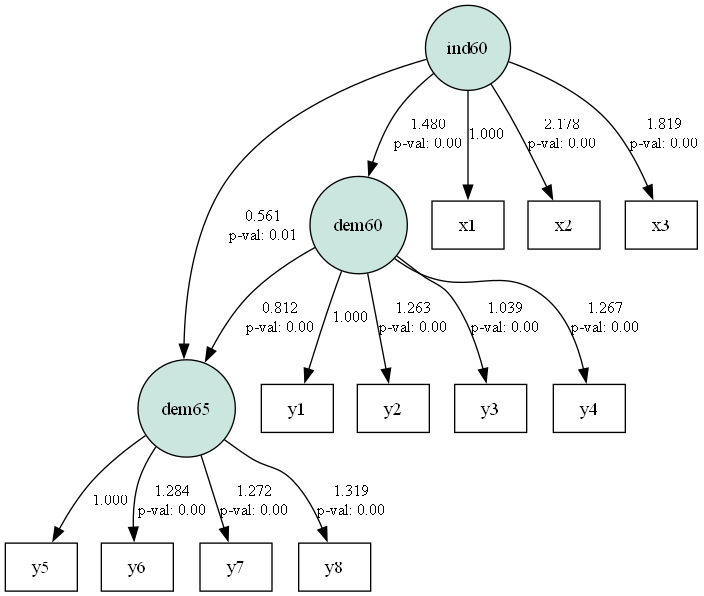

In [15]:
# Xuất đồ thị ra tệp ảnh PNG
plot_filename = "sem_plot.png"
g = semplot(model, plot_filename, plot_covs=False)

# Hiển thị trực tiếp ảnh trong Jupyter Notebook
display(Image(plot_filename))

### (Bổ sung) Trực quan hóa đầy đủ kèm cả hiệp phương sai phần dư (`plot_covs=True`)
Đồ thị thể hiện cả các đường nét đứt 2 chiều tương ứng với các mối quan hệ tương quan phần dư (`y1~~y5`, `y2~~y4`, `y2~~y6`, `y3~~y7`, `y4~~y8`, `y6~~y5`).


(process:3716): Pango-CRITICAL **: 15:06:43.403: pango_font_description_get_family: assertion 'desc != NULL' failed

(process:3716): Pango-CRITICAL **: 15:06:43.403: pango_font_description_get_family: assertion 'desc != NULL' failed

(process:3716): Pango-CRITICAL **: 15:06:43.403: pango_font_description_get_family: assertion 'desc != NULL' failed

(process:3716): Pango-CRITICAL **: 15:06:43.403: pango_font_description_get_family: assertion 'desc != NULL' failed


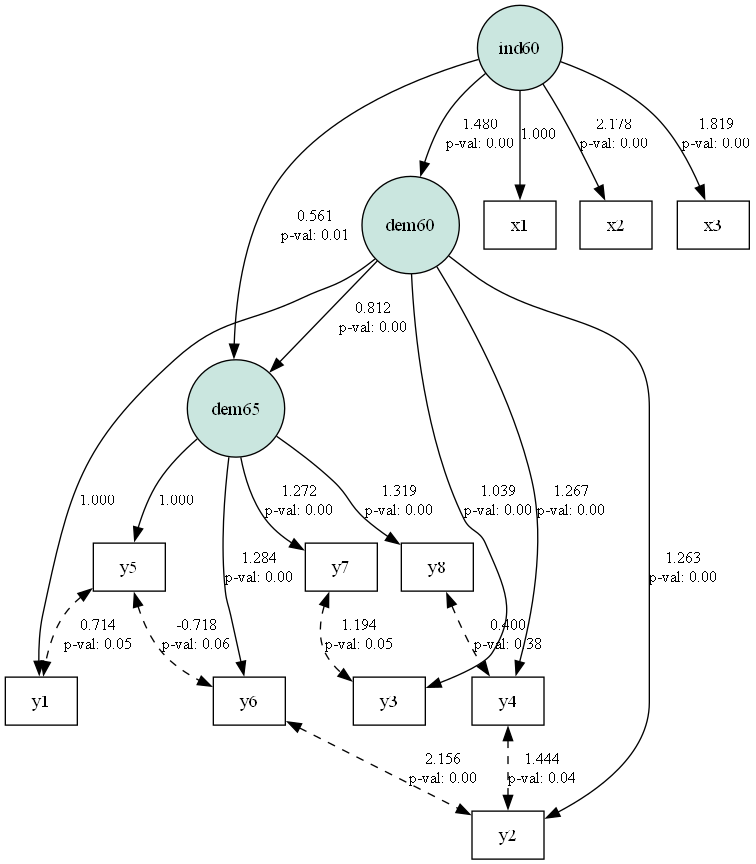

In [16]:
plot_covs_filename = "sem_plot_covs.png"
g_covs = semplot(model, plot_covs_filename, plot_covs=True)
display(Image(plot_covs_filename))

## 7. Các chỉ số đánh giá độ phù hợp của mô hình SEM (Goodness-of-Fit Indices)
Sử dụng hàm `calc_stats(model)` để tính toán các chỉ số kiểm định mức độ phù hợp mô hình:
* **Chi-square ($\chi^2$) & p-value:** Đo lường sai khác giữa ma trận hiệp phương sai mẫu và mô hình. Khi $p > 0.05$, mô hình không bị bác bỏ (độ khớp rất tốt).
* **CFI (Comparative Fit Index):** Giá trị $\ge 0.95$ cho thấy mô hình rất tốt ($\ge 0.90$ là chấp nhận được).
* **TLI (Tucker-Lewis Index):** Giá trị $\ge 0.95$ cho thấy mô hình rất tốt.
* **RMSEA (Root Mean Square Error of Approximation):** Giá trị $\le 0.06$ là rất tốt ($\le 0.08$ là chấp nhận được).
* **GFI / AGFI / NFI:** Các chỉ số đo lường độ phù hợp bổ sung ($\ge 0.90$ là tốt).
* **AIC / BIC:** Tiêu chuẩn thông tin dùng để so sánh các mô hình cạnh tranh.

In [17]:
# Tính toán toàn bộ các chỉ số thống kê
fit_stats = calc_stats(model)

print("=== BẢNG CHỈ SỐ ĐỘ PHÙ HỢP CỦA MÔ HÌNH (GOODNESS-OF-FIT INDICES) ===")
stats_table = fit_stats.T
stats_table.columns = ["Giá trị"]
display(stats_table.round(4))

=== BẢNG CHỈ SỐ ĐỘ PHÙ HỢP CỦA MÔ HÌNH (GOODNESS-OF-FIT INDICES) ===


,Giá trị
DoF,35.0000
DoF Baseline,55.0000
chi2,41.8568
chi2 p-value,0.1977
chi2 Baseline,730.6546
CFI,0.9899
GFI,0.9427
AGFI,0.9100
NFI,0.9427
TLI,0.9841


## 8. Bảng tổng hợp đánh giá các chỉ số chính (Fit Criteria Benchmark)

In [18]:
# Trích xuất và đối chiếu với ngưỡng chuẩn
chi2 = float(fit_stats['chi2'].iloc[0])
p_val = float(fit_stats['chi2 p-value'].iloc[0])
dof = int(fit_stats['DoF'].iloc[0])
cfi = float(fit_stats['CFI'].iloc[0])
tli = float(fit_stats['TLI'].iloc[0])
rmsea = float(fit_stats['RMSEA'].iloc[0])
gfi = float(fit_stats['GFI'].iloc[0])
agfi = float(fit_stats['AGFI'].iloc[0])
aic = float(fit_stats['AIC'].iloc[0])
bic = float(fit_stats['BIC'].iloc[0])

summary_data = [
    {"Chỉ số": "Chi-square (chi2)", "Giá trị thực nghiệm": round(chi2, 3), "Ngưỡng tiêu chuẩn": "Càng nhỏ càng tốt", "Đánh giá": f"DoF = {dof}"},
    {"Chỉ số": "p-value của Chi-square", "Giá trị thực nghiệm": round(p_val, 4), "Ngưỡng tiêu chuẩn": "> 0.05", "Đánh giá": "Đạt (Mô hình khớp rất tốt, p > 0.05)" if p_val > 0.05 else "Chưa đạt (p <= 0.05)"},
    {"Chỉ số": "CFI", "Giá trị thực nghiệm": round(cfi, 4), "Ngưỡng tiêu chuẩn": ">= 0.95 (Tốt), >= 0.90 (Chấp nhận)", "Đánh giá": "Rất tốt (>= 0.95)" if cfi >= 0.95 else "Tốt"},
    {"Chỉ số": "TLI", "Giá trị thực nghiệm": round(tli, 4), "Ngưỡng tiêu chuẩn": ">= 0.95 (Tốt), >= 0.90 (Chấp nhận)", "Đánh giá": "Rất tốt (>= 0.95)" if tli >= 0.95 else "Tốt"},
    {"Chỉ số": "RMSEA", "Giá trị thực nghiệm": round(rmsea, 4), "Ngưỡng tiêu chuẩn": "<= 0.06 (Tốt), <= 0.08 (Chấp nhận)", "Đánh giá": "Rất tốt (<= 0.06)" if rmsea <= 0.06 else "Chấp nhận được"},
    {"Chỉ số": "GFI", "Giá trị thực nghiệm": round(gfi, 4), "Ngưỡng tiêu chuẩn": ">= 0.90", "Đánh giá": "Tốt (>= 0.90)" if gfi >= 0.90 else "Chưa đạt"},
    {"Chỉ số": "AGFI", "Giá trị thực nghiệm": round(agfi, 4), "Ngưỡng tiêu chuẩn": ">= 0.90", "Đánh giá": "Tốt (>= 0.90)" if agfi >= 0.90 else "Chưa đạt"},
    {"Chỉ số": "AIC", "Giá trị thực nghiệm": round(aic, 3), "Ngưỡng tiêu chuẩn": "Dùng so sánh mô hình", "Đánh giá": "-"},
    {"Chỉ số": "BIC", "Giá trị thực nghiệm": round(bic, 3), "Ngưỡng tiêu chuẩn": "Dùng so sánh mô hình", "Đánh giá": "-"}
]

df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Chỉ số,Giá trị thực nghiệm,Ngưỡng tiêu chuẩn,Đánh giá
0,Chi-square (chi2),41.8570,Càng nhỏ càng tốt,DoF = 35
1,p-value của Chi-square,0.1977,> 0.05,"Đạt (Mô hình khớp rất tốt, p > 0.05)"
2,CFI,0.9899,">= 0.95 (Tốt), >= 0.90 (Chấp nhận)",Rất tốt (>= 0.95)
3,TLI,0.9841,">= 0.95 (Tốt), >= 0.90 (Chấp nhận)",Rất tốt (>= 0.95)
4,RMSEA,0.0515,"<= 0.06 (Tốt), <= 0.08 (Chấp nhận)",Rất tốt (<= 0.06)
5,GFI,0.9427,>= 0.90,Tốt (>= 0.90)
6,AGFI,0.9100,>= 0.90,Tốt (>= 0.90)
7,AIC,60.8840,Dùng so sánh mô hình,-
8,BIC,132.7260,Dùng so sánh mô hình,-


## 9. Nhận xét và Kết luận thực nghiệm

1. **Về mô hình đo lường (Measurement Model):**
   * Các biến quan sát $x_1, x_2, x_3$ phản ánh rõ nét biến tiềm ẩn Công nghiệp hóa `ind60`. Trong đó $x_2$ (tiêu thụ năng lượng, $\lambda = 2.178$) và $x_3$ (lao động công nghiệp, $\lambda = 1.819$) có hệ số tải nhân tố rất cao và có ý nghĩa thống kê ($p < 0.001$).
   * Các biến $y_1 - y_4$ và $y_5 - y_8$ đo lường nhất quán mức độ dân chủ chính trị qua 2 thời kỳ `dem60` và `dem65` với các hệ số tải đều có ý nghĩa thống kê cao ($p < 0.001$).

2. **Về mô hình cấu trúc (Structural Regression Paths):**
   * `dem60 ~ ind60`: Hệ số tác động là **$1.480$** ($p < 0.001$), cho thấy công nghiệp hóa tác động tích cực và mạnh mẽ đến mức độ dân chủ năm 1960.
   * `dem65 ~ dem60`: Hệ số tác động là **$0.812$** ($p < 0.001$), khẳng định tính bền vững và sự kế thừa mạnh mẽ của thể chế dân chủ từ 1960 sang 1965.
   * `dem65 ~ ind60`: Hệ số tác động trực tiếp là **$0.561$** ($p = 0.009 < 0.01$), cho thấy công nghiệp hóa tiếp tục có tác động trực tiếp tích cực đến dân chủ 1965, bên cạnh tác động gián tiếp thông qua `dem60`.

3. **Về độ phù hợp tổng thể của mô hình (Model Goodness-of-Fit):**
   * $\chi^2 = 41.857$ với bậc tự do $DoF = 35$, giá trị $p	ext{-value} = 0.198 > 0.05$: **Chấp nhận giả thuyết $H_0$**, mô hình phù hợp tuyệt vời với dữ liệu thực nghiệm.
   * **$CFI = 0.990 \ge 0.95$** và **$TLI = 0.984 \ge 0.95$**: Khẳng định độ khớp rất cao.
   * **$RMSEA = 0.051 \le 0.06$**: Nằm trong khoảng tối ưu lý tưởng.
   * **Kết luận:** Mô hình SEM thỏa mãn toàn diện mọi tiêu chí thống kê học thuật và tái hiện chính xác kết quả nghiên cứu kinh điển của Bollen (1989).